# Машинное обучение, ФКН ВШЭ

## Практическое домашнее задание 3.2  Продвинутая генерация признаков

### Общая информация

Дата выдачи: 31.10.2026

Мягкий дедлайн: 13.11.2026 23:59MSK

Жесткий дедлайн: 18.11.2026 23:59MSK

### О задании

В данном задании вы познакомитесь с менее тривиальными подходами для создания новых признаков в табличном машинном обучении. Вам понадобится подумать над тем, зачем мы делаем те или иные преобразования, научиться принимать решения, дающие наилучшие результаты, и узнать, как реализовывать их при помощи библиотек

### Оценивание и штрафы

См. базовую часть

### Формат сдачи
Задания сдаются через систему Anytask. Инвайт можно найти на странице курса. Присылать необходимо ноутбук с выполненным заданием. Сам ноутбук называйте в формате **homework-practice-03-advanced-Username.ipynb**, где Username — ваша фамилия.

### **Введение**

В этой части ноутбука задания посложнее дефолтного фит трансформа. Максимальная оценка за оба — 8 баллов, остальное вы можете получить, если примете участие в соревновании, и всего можете выбить аж 13 из 10. Тут ожидается больше самостоятельности, как от (почти) полноценной рабочей единицы: 
- Вы **сами** решаете, что <font color="#cb9255">**хотите**</font> делать. Пункты можно делать частично, можно скипать или сделать часть, **максимум баллов ограничен двумя**. **Посмотрите на все из них**, прежде чем приступать
- Вы **сами** чистите данные, если чуете в них подвох (теперь они далеко не такие няшные)
- Вы **сами** <font color="#f68c9d">**обосновываете**</font> (в голове, если не указано явно), могут они вам вообще помочь или нет (часть пунктов явно сильнее других)

Все прочие пожелания по тому, как строить графики, на чём фиттить, а на чём предиктить, сохраняются, будьте внимательны. Во всех пунктах с 📈 нужно добиться хотя бы минимального улучшения, относительно бейзлайна (того, что вышло в части **base**) чтобы получить балл (даже если улучшение на 0.005)

Ещё раз обратите внимание, что **максимум за advanced часть — 2 балла**, делать всё не нужно, только самое приятное. Мы в вас верим!

In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import category_encoders as ce
import sklearn
import optuna
import joblib

from scipy.sparse import csr_array
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.utils.validation import check_is_fitted

from optuna.importance import (
    FanovaImportanceEvaluator,
    get_param_importances
)
from optuna.visualization.matplotlib import plot_param_importances

from math import remainder
from narwhals.exceptions import ColumnNotFoundError
from pandas.core.reshape import merge
from sympy import true

In [2]:
def add_features(X):
    X = X.copy()
    X['day_of_week'] = pd.to_datetime(X['date']).dt.dayofweek
    X['mmr_missing'] = X['avg_mmr'].isna().astype(int)
    return X


class HeroesEncoder(TransformerMixin, BaseEstimator):
    def __init__(self, players, hero_ids):
        self.players = players
        self.hero_ids = hero_ids

    def fit(self, X, y=None):
        self.hero_index_ = pd.Index(self.hero_ids)

        return self

    def transform(self, X):
        check_is_fitted(self, 'hero_index_')

        match_index = pd.Index(X['match_id'])

        p = self.players.loc[
            self.players['match_id'].isin(match_index),
            ['match_id', 'hero_id', 'player_slot']
        ]

        rows = match_index.get_indexer(p['match_id'])
        cols = self.hero_index_.get_indexer(p['hero_id'])

        radiant = p['player_slot'].isin(range(5)).to_numpy()

        values = np.where(radiant, 1, -1).astype(np.int8)

        sparse_mx = csr_array(
            (values, (rows, cols)),
            shape=(len(match_index), len(self.hero_index_))
        )
        sparse_mx.indices = sparse_mx.indices.astype(np.int32, casting='same_kind')
        sparse_mx.indptr = sparse_mx.indptr.astype(np.int32, casting='same_kind')

        return sparse_mx

import joblib

best_pipeline = joblib.load('best_pipeline.joblib')
matches_train = joblib.load('matches_train.joblib')
X_main_train = joblib.load('X_main_train.joblib')
y_main_train = joblib.load('y_main_train.joblib')

In [80]:
matches_test = pd.read_csv('matches_df_test.csv')

In [3]:
heroes = pd.read_csv('Constants.Heroes.csv')
dota_adv = pd.read_csv('dota_adv.csv')
players = (
    best_pipeline
    .named_steps['column_transformer']
    .named_transformers_['heroes']
    .players
)

### **Часть 4. Текста** (1.5 балла) <img align="center" src="https://static.wikia.nocookie.net/dota2_gamepedia/images/4/4f/Emoticon_blush.gif/revision/latest?cb=20180504011409">

В которой студент знакомится с внутренним миром дотеров

#### **Задание 4.1. Предобработка текста** (0.75 балла)

<span style="color:grey"><font size="1">Если вам когда-либо приходила в голову мысль, что создание Интернета было ошибкой, то, что ж, после этого задания сомнения могут отпасть.</font></span>

Для некоторых матчей имеется информация о том, что писали местные аборигены, в течение тех же **15 минут от начала матча**. К сожалению, доселе мы работали лишь с таблицами, а не с текстами, но не беда, простейшие подходы нейросетей не требуют, а в простых задачах, вроде бинарной классификации, работать будут не хуже

Откройте датафрейм `game_chat.csv`, выведите парочку текстов, посмотрите, как они устроены, как там хранятся множественные сообщения,  и так далее, что у нас есть, а чего, увы, нет

In [4]:
chat = pd.read_csv('game_chat.csv')

In [5]:
chat.head()

,match_id,radiant_chat,dire_chat
0,235435,потренируйся с ботами????,саппортам | U LAGGING BRAH | stack..... | шлюх
1,102127,NaN,NaN
2,383046,u just buy levels blue? | fa ge,NaN
3,729879,NaN,NaN
4,126886,NaN,NaN


Дём дальше. Тексты нужно готовить, прежде чем пихать их в модель. Оценивать выбросы здесь довольно проблематично, в силу специфики дотерских сообщений, хотя вы, конечно, можете попытаться. Речь здесь про базовую предобработку.

Задача минимум, тут мы вам поможем:
- Разобраться с библиотекой `nltk` и разбить текст на токены — отдельные сущности, составляющие текст (чаще всего слова, но бывает и что-то другое, надо разобраться). Как бить текст — вопрос неоднозначный. В целом подойдёт любой способ, но какие-то [токенизаторы](https://www.nltk.org/api/nltk.tokenize.html) могут сразу покрыть часть проблем с текстами в задаче максимум
- Лемматизировать текст (привести слова к начальной форме). <br>
<font color="#cb9255">**Варианта два**</font>: манкипатчить [`pymorphy2`](https://pymorphy2.readthedocs.io/en/stable/) или откатывать версии (там вылезет ошибка, если у вас слишком новый питон), либо применять [`mystem`](https://pypi.org/project/pymystem3/), что может затянуться на несколько часов, зато лемматизация будет точнее

Задача максимум, тут вам нужно понять, как всё обработать, самим (включать-не включать, выкинуть-оставить — валидны **все** варианты, но только, если, есть, <font color="#f68c9d">**обоснование**</font>):
- повторы символов
- знаки препинания
- стоп-слова
- нижний регистр
  
Вам нужно пройтись по всем пунктам, не обязательно в этом порядке. Если найдёте что-то ещё — круто, молодцы, можно тоже пофиксить

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">




**Вопрос:** ну что, как обрабатываем текст?

**Ответ:** Использую `TweetTokenizer`. Точки и запятые уберу, а вопросительные и восклицательные знаки оставлю: в чате они могут передавать интонацию. Символ `|` разделяет сообщения. Можно токенизировать каждое сообщение отдельно, но для этого эксперимента беру чат каждой команды за матч как один текст. Токены привожу к нижнему регистру, длинные повторы сокращаю до трёх символов, стоп-слова оставляю.

</div>

In [6]:
from nltk.tokenize import TweetTokenizer
import pymorphy3
import re
from nltk.stem import WordNetLemmatizer

english_lematizer = WordNetLemmatizer()
morph = pymorphy3.MorphAnalyzer()
tokenizer = TweetTokenizer(
    preserve_case=False,
    reduce_len=True
)

def preprocessing(text: str):
    tokens = tokenizer.tokenize(text)
    tokens = [
        token
        for token in tokens
        if re.fullmatch(r'[.,|]+', token) is None
    ]
    lemmas = [morph.parse(token)[0].normal_form for token in tokens]
    lemmas = [english_lematizer.lemmatize(token) for token in lemmas]
    return lemmas


print(preprocessing("Ляяя, ваша мама такая красивая, ну вылитый пудж)))0 hello dexter morgan please canwe meet next times biig"))

['ляять', 'ваш', 'мама', 'такой', 'красивый', 'ну', 'вылитый', 'пуджа', ')', ')', ')', '0', 'hello', 'dexter', 'morgan', 'please', 'canwe', 'meet', 'next', 'time', 'biig']


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    token_pattern=None,
    lowercase=False,
    stop_words=None,
    ngram_range=(1, 1)
)

#### 📈 **Задание 4.2. Векторизация** (0.5 балла)

Ура, если у вас получились токены, то наконец-то можно что-то закодировать, но как? Рад, что вы спросили. Читайте конспект семинаров или документацию

<table width="800" border="1" cellpadding="8" cellspacing="0">
  <tr>
    <th width="50%">
      <font color="#cb9255">CountVectorizer</font>
    </th>
    <th width="50%">
      <font color="#cb9255">TfIdfVectorizer</font>
    </th>
  </tr>
  <tr>
    <td valign="top">
      Берёт и считает, сколько раз в тексте <br>
      встретилось то или иное слово. Похож <br>
      на наш энкодер из части 2.
      <br><br>
      <table border="1" cellpadding="4" cellspacing="0">
        <thead>
          <tr>
            <th scope="col">word_1</th>
            <th scope="col">word_2</th>
            <th scope="col">word_3</th>
            <th scope="col">...</th>
            <th scope="col">word_m</th>
          </tr>
        </thead>
        <tbody>
          <tr>
            <td>1</td>
            <td>0</td>
            <td>2</td>
            <td>...</td>
            <td>100</td>
          </tr>
        </tbody>
      </table>
    </td>
    <td valign="top">
      Более хитрая штука: вместе с количеством слов (tf)<br>
      считает их важность (idf). Слова, встречающиеся <br>
      во всех документах, считаются не важными<br>
      и зануляются (idf = log1).
      <br><br>
      <table border="1" cellpadding="4" cellspacing="0">
        <thead>
          <tr>
            <th scope="col"></th>
            <th scope="col">word_1</th>
            <th scope="col">word_2</th>
            <th scope="col">word_3</th>
            <th scope="col">...</th>
            <th scope="col">word_m</th>
          </tr>
        </thead>
        <tbody>
          <tr>
            <td><b>text_1</b></td>
            <td>1*log2</td>
            <td>0</td>
            <td>2*log2</td>
            <td>...</td>
            <td>100*log1</td>
          </tr>
          <tr>
            <td><b>text_2</b></td>
            <td>0</td>
            <td>10*log2</td>
            <td>0</td>
            <td>...</td>
            <td>100*log1</td>
          </tr>
        </tbody>
      </table>
    </td>
  </tr>
</table>


Оба векторайзера хороши, но у каждого из них есть <font color="#cb9255">**гиперпараметры**</font>. Естественно, они повлияют на качество, <font color="#cb9255">**можете подобрать их**</font> попозже, дефолтные тоже должны показать эффект

Обучите по векторайзеру на чатах Radiant и Dire. Приклейте результат к вашему датасету и обучите модель на всём получившемся великолепии (sparse формат убирать не рекомендуется)

In [8]:
X_train_with_chat = pd.merge(
    X_main_train,
    chat,
    on='match_id',
    how='left',
    validate='one_to_one'
)
X_train_with_chat.index = X_main_train.index

text_columns = ['radiant_chat', 'dire_chat']

X_train_with_chat[text_columns] = (
    X_train_with_chat[text_columns].fillna('')
)

In [9]:
from sklearn.base import clone

cv = TimeSeriesSplit(n_splits=5)

hero_ids = heroes['id'].dropna().unique()

mmr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('sqrt', FunctionTransformer(np.sqrt)),
    ('scaling', StandardScaler())
])

column_transformer = ColumnTransformer([
    ('ohe', ce.OneHotEncoder(cols=['region', 'day_of_week']), ['region', 'day_of_week']),
    ('mmr', mmr_pipeline, ['avg_mmr']),
    ('flags', 'passthrough', ['mmr_missing']),
    ('heroes', HeroesEncoder(players=players, hero_ids=hero_ids), ['match_id']),
    ('radiant_chat', clone(vectorizer), 'radiant_chat'),
    ('dire_chat', clone(vectorizer), 'dire_chat'),
], remainder='drop')

pipeline = Pipeline([
    ('features', FunctionTransformer(add_features)),
    ('column_transformer', column_transformer),
    ('model', clone(best_pipeline.named_steps['model'])),
])

In [10]:
scores = cross_val_score(
    pipeline,
    X_train_with_chat,
    y_main_train,
    cv=cv,
    scoring='roc_auc',
    error_score='raise'
)

print('Gini: ', 2 * scores.mean() - 1)

Gini:  0.3155352087700847


#### **Задание 4.3. Визуализация** (0.25 балла)

Для любителей графиков есть малюсенькое задание: визуализируйте облако слов с наибольшими по модулю весами (разделите их на условно *"позитивные"* и *"негативные"*)

In [11]:
pipeline.fit(X_train_with_chat, y_main_train)

model = pipeline.named_steps['model']
transformer = pipeline.named_steps['column_transformer']

weights = model.coef_[0]

# получаем все слова из векторайзера
words = transformer.named_transformers_['radiant_chat'].get_feature_names_out()

# получаем слайс - от и до какого индекса стоят нужные нам И затем получаем их веса
radiant_weights = weights[transformer.output_indices_['radiant_chat']]

word_weights = pd.Series(
    radiant_weights,
    index=words,
    name='weight'
)

positive = word_weights[word_weights > 0].nlargest(30)
negative = word_weights[word_weights < 0].nsmallest(30).abs()

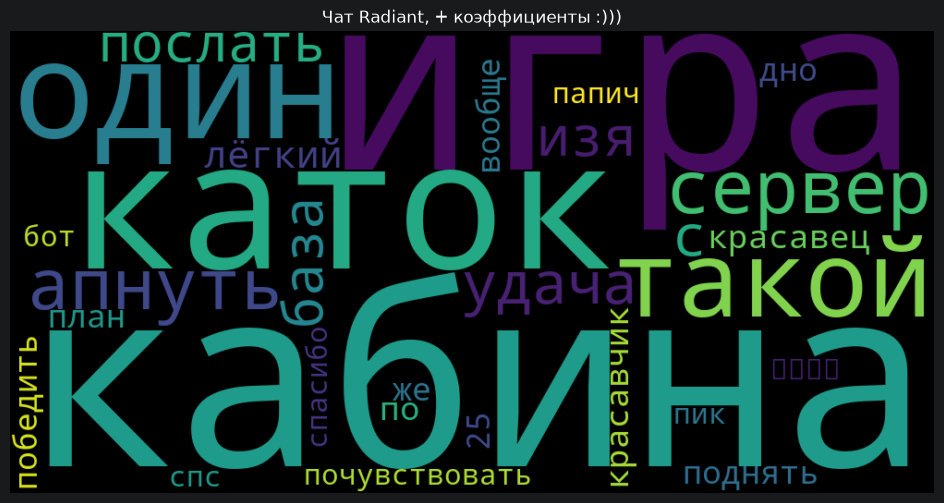

In [96]:
from wordcloud import WordCloud

cloud = WordCloud(
    width=1000,
    height=500,
    background_color='black',
    max_words=30,
    random_state=42,
).generate_from_frequencies(positive.to_dict())

plt.figure(figsize=(12, 6))
plt.imshow(cloud, interpolation='bilinear')
plt.axis('off')
plt.title('Чат Radiant, + коэффициенты :)))')
plt.show()

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** что думаете? Сейчас и вообще по модели — негативные получились слова или так, едва?

**Ответ:** Облако слов в целом интерпретируемо: для части слов с отрицательными коэффициентами можно предположить, в каких выражениях и ситуациях они встречаются.

</div>

### **Часть 5. Агрегации** (1.75 балла) <img align="center" src="https://static.wikia.nocookie.net/dota2_gamepedia/images/4/4a/Techies_emoticon.gif/revision/latest?cb=20180504014918">

В которой студент начинает ведать

#### 📈 **Задание 5.1. Статистики матча** (0.75 балла)

Есть у нас в данных большой кусок про advantage — преимущество команды сил Света с точностью до минуты, по золоту и опыту, всё так же **в пределах 15 минут**. Лежат они в `dota_adv.csv`. Чем больше число, тем больше шанс на победу — всё просто. Только график, как правило, не линеен.

С ними в очередной раз есть *нюансы* — необходимо разобраться, как они там лежат, и всё ли там в порядке со значениями, но это меньшая из проблем. А также нарисовать парочку advantage, чтобы было понимание, как они себя ведут

In [21]:
dota_adv.iloc[0]['radiant_gold_adv']

'[   0  159  452 1904 2100 3290 3290 3290 3290 3859 3859 3087 3087 3849\n 5342 5342]'

In [25]:
balls = pd.merge(
    X_train_with_chat,
    dota_adv,
    on='match_id',
    how='left',
)

Для начала возьмём простые агрегации. Можете взять те, что вам знакомы (статистики - среднее, стд и др.), можете взять фан факты в вашей любимой библиотеке для данных, например [тут](https://pandas.pydata.org/docs/user_guide/groupby.html#aggregation) или [тут](https://docs.pola.rs/api/python/stable/reference/expressions/aggregation.html).

Задание:
- взять 4 статистики из библиотеки, применить к обеим колонкам `_adv`, <font color="#f68c9d">**обдумать**</font>, почему именно они
- одну из статистику выше разбить по командам, и точно так же примените к колонкам (получится что-то типа `agg_xp` -> `agg_dire_xp`, `agg_radiant_xp`)

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Тут мы встаём на скользкую дорожку переобучения. Агрегаций можно сделать **очень** много. Добавьте их все, и ваша модель превратится в тыкву. Удобнее будет сразу бить их на группы, например `features_last`, `features_q25`, `features_kurtosis_dire_10min+` и так далее, в зависимости от степени упоротости

C другой стороны, агрегации это самая сильная группа фичей, и для десяточки лучше целиться именно в них

</div>

<div style="border-left: 5px solid #f68c9d; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** какие агрегации берём?

**Ответ:** Начну с простых агрегаций и посмотрю, как они влияют на качество. По результатам решу, стоит ли добавлять другие статистики.

</div>

Обучите модель по агрегациям (одной группе или нескольким) + предыдущим фичам. Чтобы получить фулл балл, придётся показать, что хотя бы минимальный импрув есть, относительно бейзлайна


In [27]:
def parse_adv(s):
    if pd.isna(s):
        return np.array([], dtype=float)

    values = s.strip().strip('[]').split()
    return np.array(values, dtype=float)

In [59]:
def median_lead(lead):
    if len(lead) == 0:
        return np.nan

    positive_lead = lead[lead > 0]
    return np.median(positive_lead) if len(positive_lead) > 0 else 0

def add_adv_features(X):
    X = X.copy()
    xp = X['radiant_exp_adv'].map(parse_adv)
    # X['xp_last5mean'] = xp.map(lambda x: np.mean(x[-5:]) if len(x) else np.nan)
    # X['xp_quantile'] = xp.map(lambda x: np.quantile(x, 0.75) if len(x) else np.nan)
    X['xp_last'] = xp.map(lambda x: x[-1] if len(x) else np.nan)
    X['xp_radiant_median'] = xp.map(median_lead)
    X['xp_dire_median'] = xp.map(lambda x: median_lead(-x))

    gold = X['radiant_gold_adv'].map(parse_adv)
    # X['gold_last5mean'] = gold.map(lambda x: np.mean(x[-5:]) if len(x) else np.nan)
    # X['gold_quantile'] = gold.map(lambda x: np.quantile(x, 0.75) if len(x) else np.nan)
    X['gold_last'] = gold.map(lambda x: x[-1] if len(x) else np.nan)
    X['gold_radiant_median'] = gold.map(median_lead)
    X['gold_dire_median'] = gold.map(lambda x: median_lead(-x))

    return X

In [75]:
pipeline_with_adv = clone(pipeline)

adv_columns = [
    'xp_last', 'xp_radiant_median', 'xp_dire_median',
    'gold_last', 'gold_radiant_median', 'gold_dire_median',
]

adv_numeric = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ct = pipeline_with_adv.named_steps['column_transformer']
ct.set_params(transformers=[
    *ct.transformers,
    ('adv_numeric', adv_numeric, adv_columns)
])

pipeline_with_adv.steps.insert(
    1, ('adv_features', FunctionTransformer(add_adv_features))
)

In [68]:
X_train_chat_adv = pd.merge(
    X_train_with_chat,
    dota_adv,
    on='match_id',
    how='left',
)
X_train_chat_adv.index = X_train_with_chat.index

In [31]:
print('Old Gini: ', 2 * scores.mean() - 1)

scores_with_adv = cross_val_score(
    pipeline_with_adv,
    X_train_chat_adv,
    y_main_train,
    cv=cv,
    scoring='roc_auc',
    error_score='raise'
)

print('Adv Gini: ', 2 * scores_with_adv.mean() - 1)

Old Gini:  0.3155352087700847


/Users/baloomba5/ML_Jupyter/ml-course-hse/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/baloomba5/ML_Jupyter/ml-course-hse/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/baloomba5/ML_Jupyter/ml-course-hse/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/baloomba5/ML_Jupyter/ml-course-hse/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Adv Gini:  0.3955836697033206


In [76]:
pipeline_lbfgs = clone(pipeline_with_adv)
pipeline_lbfgs.set_params(model__solver='lbfgs')

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('adv_features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...t 0x10cbf6140>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDic

In [38]:
scores_with_adv_2 = cross_val_score(
    pipeline_lbfgs,
    X_train_chat_adv,
    y_main_train,
    cv=cv,
    scoring='roc_auc',
    error_score='raise'
)

print('Adv Gini (solver=lbfgs)', 2 * scores_with_adv_2.mean() - 1)

Adv Gini (solver=lbfgs) 0.40065526834103915


#### 📈 **Задание 5.2. Тренд** (0.5 балла)

Каждый уважающий себя лудоман знает, что 99% процентов игроков останавливается ровно перед тем, как сорвать джекпот. Так и здесь — если команда с треском проигрывает в первые 15 минут матча, возможно это признак камбека в следующие 50, как знать? Попробуем собрать агрегацию похитрее — она будет обозначать тренд, который есть в графиках преимущества, и если пословица верна, наша модель уловит эту зависимость.

<span style="color:grey"><font size="1">Администрация курса МО-1 категорически против азартных игр, пример приводится сугубо в образовательных целях.</font></span>

<div style="border-left: 5px solid #f68c9d; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** для чего нам вообще тренд? Полезная ли это агрегация?

**Ответ:** Тренд может помочь в матчах, где сначала вела одна команда, а ближе к концу наблюдения другая начала её догонять. Даже если текущий перевес невелик, направление его изменения может быть информативным.

</div>

Агрегировать можно и вещи несколько более прикольные, чем те, что есть в основном функционале. Делать это мы будем, как вы наверняка догадались, трансформером, ну а чем же ещё. Что он умеет?

1. Принимает на вход функцию колонку и <font color="#cb9255">**параметры**</font> на ваш вкус, как минимум `method`, метод расчёта `slope`
2. Выделяет коэффициент наклона (`slope`, он же $\alpha$) при помощи одного из методов:
   - `'delta'`: разность первого и последнего значений $|x_{\max} - x_{\min}|$
   - `'OLS'`: линейная регрессия, обученная методом МНК $(X^TX)^{-1}X^Ty$
   - альтернативный метод, порождённый вашей бурной фантазией
3. Считает `r2` и `intercept` для одного advantage (если что это тоже могут быть наши фичи!)

In [69]:
from typing import Iterable
from sklearn.metrics import r2_score

class TrendTransformer:

    def __init__(self, columns: Iterable[str]):
        self.columns = columns
        self.method = 'ols'

    def _trend_for_match(self, adv):
        if (len(adv) < 2):
            return np.nan, np.nan, np.nan
        t = np.arange(len(adv))
        slope, intercept = np.polyfit(t, adv, deg=1)
        predicted = intercept + slope * t

        return slope, intercept, r2_score(adv, predicted)

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        X = X.copy()

        xp = X['radiant_exp_adv'].map(parse_adv)
        results = xp.map(self._trend_for_match)
        X[['xp_slope', 'xp_intercept', 'xp_r2']] = pd.DataFrame(results.tolist(), index=X.index)

        gold = X['radiant_gold_adv'].map(parse_adv)
        results = gold.map(self._trend_for_match)
        X[['gold_slope', 'gold_intercept', 'gold_r2']] = pd.DataFrame(results.tolist(), index=X.index)

        return X

Реализуйте трансформер. Критерий успеха, вновь, качество — фича должна помочь, хотя бы на долю пункта

In [77]:
pipeline_with_trend = clone(pipeline_lbfgs)

adv_columns = [
    'xp_slope', 'xp_intercept', 'xp_r2',
    'gold_slope', 'gold_intercept', 'gold_r2'
]

adv_trend = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ct = pipeline_with_trend.named_steps['column_transformer']
ct.set_params(transformers=[
    *ct.transformers,
    ('adv_trend', adv_trend, adv_columns)
])

pipeline_with_trend.steps.insert(
    1, ('adv_trend', TrendTransformer(columns=['radiant_exp_adv', 'radiant_gold_adv']))
)

In [39]:
score_with_trend = cross_val_score(
    pipeline_with_trend,
    X_train_chat_adv,
    y_main_train,
    cv=cv,
    scoring='roc_auc',
    error_score='raise'
)

print('Gini with trend: ', 2 * score_with_trend.mean() - 1)

Gini with trend:  0.4017397733678665


#### **📈 Задание 5.3. Бинаризация** (0.5 балла)


Ровно одну прикольную фишку для числовых признаков мы пока что не рассмотрели — бинаризацию. Если вы до неё уже догадались, то вы — гений, не думали на <font color="cb9255">**МОП**</font>? А если нет, суть такова:

1. Берём отрезок advantage и бьём его на несколько бинов
2. Бины можно использовать, как фичу саму по себе, а можно подсобрать внутри неё агрегации

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Во-первых, ваша модель внезапно становится нелинейной, хоть и кусочной, это полный отвал \
Во-вторых, это простейший пример ансамбля, если бинаризовать таргет (но у нас, увы нет смысла, он дискретный). Нелинейность полезна почему — в первые минуты преимущество не так решает, как в последние. \
В-третьих, это фильтрует шумный сигнал, выбросы то отлетят в соответствующий бин

</div>

Попробуем? Бинаризуйте признаки advantage: занумеруйте их (сделайте категорию) и посчитайте побиновые агрегации

In [71]:
source_columns = {
    'xp': 'radiant_exp_adv',
    'gold': 'radiant_gold_adv',
}

windows = [(1, 4), (4, 7), (7, 10), (10, 13), (13, 16)]

def mean_in_window(adv, start, stop):
    part = adv[start:stop]
    return part.mean() if part.size else np.nan

In [81]:
def add_adv_binned_features(X):
    X = X.copy()

    for prefix, column in source_columns.items():
        rows = X[column].map(parse_adv)

        for start, stop in windows:
            name = f'{prefix}_mean_{start}_{stop - 1}'
            X[name] = rows.map(lambda adv: mean_in_window(adv, start, stop))

    return X

In [83]:
pipeline_binned = clone(pipeline_with_trend)

adv_binned = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

pipeline_binned.steps.insert(
    1, ('adv_binned_features', FunctionTransformer(add_adv_binned_features))
)


adv_binned_columns = [
    'xp_mean_1_3', 'xp_mean_4_6', 'xp_mean_7_9', 'xp_mean_10_12', 'xp_mean_13_15',
    'gold_mean_1_3', 'gold_mean_4_6', 'gold_mean_7_9', 'gold_mean_10_12', 'gold_mean_13_15'
]

ct = pipeline_binned.named_steps['column_transformer']

ct.set_params(transformers=[
    *ct.transformers,
    ('adv_binned', adv_binned, adv_binned_columns)])


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ohe', ...), ('mmr', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [85]:
scores_with_bins = cross_val_score(
    pipeline_binned,
    X_train_chat_adv,
    y_main_train,
    cv=cv,
    scoring='roc_auc',
    error_score='raise'
)

print('Gini with bins: ', 2 * scores_with_bins.mean() - 1)

Gini with bins:  0.4023924348153447


In [87]:
import optuna

def objective(trial):
    C = trial.suggest_float('C', 1e-4, 1e3, log=True)
    solver = 'lbfgs'
    max_iter = 1500

    pipeline = clone(pipeline_binned)
    pipeline.named_steps['model'].set_params(solver=solver, max_iter=max_iter, C=C)
    score = cross_val_score(
        pipeline,
        X_train_chat_adv,
        y_main_train,
        cv=TimeSeriesSplit(n_splits=3),
        scoring='roc_auc',
        n_jobs=1
    )

    return 2 * score.mean() - 1

study = optuna.create_study(direction="maximize")
study.optimize(objective, show_progress_bar=True, n_trials=1)

[I 2026-11-20 23:53:28,869] A new study created in memory with name: no-name-e67b31f7-dc5f-4cd6-bb7f-87a305323161
  0%|          | 0/1 [00:18<?, ?it/s]

KeyboardInterrupt



KeyboardInterrupt: 

In [91]:
study.optimize(objective, show_progress_bar=True, n_trials=3)

Best trial: 5. Best value: 0.417021:  33%|███▎      | 1/3 [03:59<07:59, 239.87s/it]

[I 2026-11-21 10:27:30,385] Trial 10 finished with value: 0.37221035717517204 and parameters: {'C': 0.00011478877327954851}. Best is trial 5 with value: 0.4170213792763764.


Best trial: 5. Best value: 0.417021:  67%|██████▋   | 2/3 [08:58<04:34, 274.30s/it]

[I 2026-11-21 10:32:28,785] Trial 11 finished with value: 0.41010237398078764 and parameters: {'C': 10.232059617996986}. Best is trial 5 with value: 0.4170213792763764.


Best trial: 5. Best value: 0.417021: 100%|██████████| 3/3 [13:04<00:00, 261.63s/it]

[I 2026-11-21 10:36:35,396] Trial 12 finished with value: 0.41160977671648524 and parameters: {'C': 0.14683543245787872}. Best is trial 5 with value: 0.4170213792763764.


In [90]:
best_pipeline = clone(pipeline_binned)
best_pipeline.named_steps['model'].set_params(
    solver='lbfgs',
    max_iter=1500,
    **study.best_params,
)
best_pipeline.fit(X_train_chat_adv, y_main_train)

X_test_chat_adv = (
    matches_test
    .merge(chat, on='match_id', how='left', validate='one_to_one')
    .merge(dota_adv, on='match_id', how='left', validate='one_to_one')
)
X_test_chat_adv[text_columns] = X_test_chat_adv[text_columns].fillna('')

submission = pd.DataFrame({
    'ID': X_test_chat_adv['match_id'],
    'VALUE': best_pipeline.predict_proba(X_test_chat_adv)[:, 1]
})
submission.to_csv('submission.csv', index=False)

submission.shape

(59748, 2)

### **Часть 6. Около ML** (2 балла) <img height=25px width=35px align="center" src="https://media1.tenor.com/m/72ScVNgTGpYAAAAC/kaneki-tokyo-ghoul.gif"></img>

В которой студент жесточайше чиллит после пережитого ужаса

#### **Задание 6.1. Пайплайн** (0.5 балла)

Работать в ноутбуках становится экспоненциально тяжелее по мере разрастания модели. Чтобы немножко упорядочить хаос, вам предлагается засунуть всё в один пайплайн. Критерии:

- функция или класс (может понравиться `ColumnTransformer` и `Pipeline`)
- возможность нажать одну кнопку, чтобы запустить пайплайн, уйти пить пиво и вернуться к уже готовому submission для Kaggle
- возможность передать флаги (какие фичи добавляем) и параметры (если есть разные варианты сбора параметров)
- включает в себя все пункты, к которым вы прикоснулись в рамках домашнего задания

А вот как именно это делать — дело ваше, для себя же стараетесь

In [104]:
adv_columns = [
    'xp_last', 'xp_radiant_median', 'xp_dire_median',
    'gold_last', 'gold_radiant_median', 'gold_dire_median',
]

adv_columns_trend = [
    'xp_slope', 'xp_intercept', 'xp_r2',
    'gold_slope', 'gold_intercept', 'gold_r2'
]

adv_binned_columns = [
    'xp_mean_1_3', 'xp_mean_4_6', 'xp_mean_7_9', 'xp_mean_10_12', 'xp_mean_13_15',
    'gold_mean_1_3', 'gold_mean_4_6', 'gold_mean_7_9', 'gold_mean_10_12', 'gold_mean_13_15'
]


hero_ids = heroes['id'].dropna().unique()

mmr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('sqrt', FunctionTransformer(np.sqrt)),
    ('scaling', StandardScaler())
])

adv_numeric = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

adv_trend = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

adv_binned = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

column_transformer = ColumnTransformer([
    ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore'),
     ['region', 'day_of_week']),
    ('mmr', mmr_pipeline, ['avg_mmr']),
    ('flags', 'passthrough', ['mmr_missing']),
    ('heroes', HeroesEncoder(players=players, hero_ids=hero_ids), ['match_id']),
    ('radiant_chat', clone(vectorizer), 'radiant_chat'),
    ('dire_chat', clone(vectorizer), 'dire_chat'),
    ('adv_numeric', adv_numeric, adv_columns),
    ('adv_trend', adv_trend, adv_columns_trend),
    ('adv_binned', adv_binned, adv_binned_columns),
], remainder='drop')

final_pipeline = Pipeline([
    ('features', FunctionTransformer(add_features)),
    ('adv_features', FunctionTransformer(add_adv_features)),
    ('adv_trend', TrendTransformer(columns=['radiant_exp_adv', 'radiant_gold_adv'])),
    ('adv_binned_features', FunctionTransformer(add_adv_binned_features)),
    ('column_transformer', column_transformer),
    ('model', LogisticRegression(solver='lbfgs', max_iter=1500)),
])

In [105]:
def objective(trial):
    C = trial.suggest_float('C', 1e-4, 1e3, log=True)
    solver = 'lbfgs'
    max_iter = 1500

    pipeline = clone(final_pipeline)
    pipeline.named_steps['model'].set_params(solver=solver, max_iter=max_iter, C=C)
    score = cross_val_score(
        pipeline,
        X_train_chat_adv,
        y_main_train,
        cv=TimeSeriesSplit(n_splits=3),
        scoring='roc_auc',
        n_jobs=1
    )

    return 2 * score.mean() - 1

study = optuna.create_study(direction="maximize")
study.optimize(objective, show_progress_bar=True, n_trials=3)

[I 2026-11-22 22:02:14,997] A new study created in memory with name: no-name-ec179a68-cb64-4a26-ad26-8a68b3617f23
  0%|          | 0/3 [00:00<?, ?it/s]/Users/baloomba5/ML_Jupyter/ml-course-hse/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/baloomba5/ML_Jupyter/ml-course-hse/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATION

[I 2026-11-22 22:06:54,101] Trial 0 finished with value: 0.39934019819016076 and parameters: {'C': 242.19273968598978}. Best is trial 0 with value: 0.39934019819016076.


Best trial: 0. Best value: 0.39934:  67%|██████▋   | 2/3 [07:54<03:49, 229.75s/it]

[I 2026-11-22 22:10:09,307] Trial 1 finished with value: 0.39634825248315253 and parameters: {'C': 0.0038657780601798926}. Best is trial 0 with value: 0.39934019819016076.


Best trial: 2. Best value: 0.416682: 100%|██████████| 3/3 [11:35<00:00, 231.99s/it]

[I 2026-11-22 22:13:50,975] Trial 2 finished with value: 0.4166821008018895 and parameters: {'C': 1.34067107117569}. Best is trial 2 with value: 0.4166821008018895.


In [106]:
best_pipeline = clone(final_pipeline)
best_pipeline.named_steps['model'].set_params(
    solver='lbfgs',
    max_iter=1500,
    **study.best_params,
)
best_pipeline.fit(X_train_chat_adv, y_main_train)

X_test_chat_adv = (
    matches_test
    .merge(chat, on='match_id', how='left', validate='one_to_one')
    .merge(dota_adv, on='match_id', how='left', validate='one_to_one')
)
X_test_chat_adv[text_columns] = X_test_chat_adv[text_columns].fillna('')

submission = pd.DataFrame({
    'ID': X_test_chat_adv['match_id'],
    'VALUE': best_pipeline.predict_proba(X_test_chat_adv)[:, 1]
})

submission.to_csv('submission.csv', index=False)

#### **Задание 6.2. Storage** (0.25 балла)

Вдогоночку можно ещё и создать псевдо-БД, чтобы хранить наши шедевры и не потеряться в тысячах моделек. Давайте вот такую штуку запилим:

- датафрейм или честная БД для версионирования моделей
- для каждой модели есть уникальный идентификатор
- для каждой модели сохраняются её гиперпараметры или параметры всего пайплайна (если вы его сделали)
- для каждой модели хранятся метрики на валидации

Сделайте и продемонстрируйте

In [107]:
from optuna.trial import TrialState

rows = []

for trial in study.trials:
    if trial.state != TrialState.COMPLETE:
        continue

    rows.append({
        'model_id': f'{study.study_name}:{trial.number}',
        'pipeline': 'final_pipeline',
        'C': trial.params['C'],
        'solver': 'lbfgs',
        'max_iter': 1500,
        'cv_n_splits': 3,
        'cv_gini': trial.value,
        'selected': trial.number == study.best_trial.number,
    })

model_registry = pd.DataFrame(rows)
display(model_registry.sort_values('cv_gini', ascending=False))

,model_id,pipeline,C,solver,max_iter,cv_n_splits,cv_gini,selected
2,no-name-ec179a68-cb64-4a26-ad26-8a68b3617f23:2,final_pipeline,1.340671,lbfgs,1500,3,0.416682,True
0,no-name-ec179a68-cb64-4a26-ad26-8a68b3617f23:0,final_pipeline,242.192740,lbfgs,1500,3,0.399340,False
1,no-name-ec179a68-cb64-4a26-ad26-8a68b3617f23:1,final_pipeline,0.003866,lbfgs,1500,3,0.396348,False


#### **Задание 6.3. CuML** (0.25 балла)

Если вы таки осмелились делать домашку именно на Kaggle, то поздравляю, пожалуй, это самое здравое решение в этой дз. Чтобы использовать его возможности по полной, пересядьте с вашей модели из `sklearn`, которую вы выбрали в задании про даты **(1.3)**, на модель из `cuml`. 

[Разберитесь](https://docs.rapids.ai/api/cuml/stable/), как они используют GPU и проведите тест-драйв на любом наборе фичей

In [ ]:
# сделал на каггле х30 ускорение на обучении

#### **Задание 6.4. High tech. Low life** (0.5 балла)

Если вы следите за новостями, то, наверное, заметили появление хайповейших LLM. Злые языки утверждают, что обычному работяге фит предиктору не место в мире будущего, и его заменит ИИ. Давайте в этом (раз)убедимся.

Попробуйте:
1. Спросить у вашей любимой нейросети, какие признаки она может для вас придумать. Можете опираться на пункты выше, можете придумать что-то свое. Но помните, что как говорится, какой стол, такой и стул, поэтому пишите промпты с умом.
2. Показать, что нейросеть вам посоветовала, и реализовать это
3. Проанализировать результат и сделать решительный вывод, хуже ли вы, чем языковая модель.

Попытайтесь либо вспомнить, либо посмотреть, что у нас ещё есть в данных. Там достаточно много полезной информации, которую мы либо совсем никак не брали, либо брали, но поверхностно, либо брали, но можно сделать ещё круче, старые пункты тоже можно доработать

In [98]:
# 6.4. Сравнение на одном OOT-сплите, затем обучение на всех матчах.
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import FunctionTransformer


def draft_counts_64(roster, hero_table):
    roles = hero_table.set_index('id')['roles'].astype(str)
    keys = [roster['match_id'], roster['player_slot'].isin(range(5))]
    counts = {}
    for role in ['Carry', 'Disabler']:
        flag = roster['hero_id'].map(roles.str.contains(role, regex=False)).fillna(False)
        sides = flag.groupby(keys, sort=False).sum().unstack().reindex(columns=[True, False])
        counts[f'{role}_radiant'] = sides.iloc[:, 0]
        counts[f'{role}_dire'] = sides.iloc[:, 1]
    return pd.DataFrame(counts)


def extra_features_64(X, draft):
    out = pd.DataFrame(index=X.index)
    leads = {}
    for resource in ['xp', 'gold']:
        last = X[f'{resource}_last']
        # Сжатие больших перевесов и отдельный наклон за порогом в 2000.
        out[f'{resource}_log_lead'] = np.sign(last) * np.log1p(last.abs())
        out[f'{resource}_large_lead'] = np.sign(last) * (last.abs() - 2000).clip(lower=0)
        bins = X[[f'{resource}_mean_{a}_{a + 2}' for a in (1, 4, 7, 10, 13)]]
        out[f'{resource}_control'] = np.sign(bins).mean(axis=1)
        recent = bins.iloc[:, -1] - bins.iloc[:, -2]
        out[f'{resource}_late_swing'] = np.sign(recent) * np.sqrt(recent.abs())
        leads[resource] = last

    gold, xp = leads['gold'], leads['xp']
    # Подтверждают ли оба ресурса лидерство одной команды?
    out['joint_lead'] = (np.sign(gold) + np.sign(xp)) / 2 * np.log1p(np.minimum(gold.abs(), xp.abs()))
    for role in ['Carry', 'Disabler']:
        radiant = X['match_id'].map(draft[f'{role}_radiant'])
        dire = X['match_id'].map(draft[f'{role}_dire'])
        # Порог создаёт взаимодействие между героями одного состава.
        threshold = 3 if role == 'Carry' else 1
        out[f'{role}_threshold'] = ((radiant >= threshold).astype(int)
                                     - (dire >= threshold).astype(int)).where(radiant.notna() & dire.notna())
        leading_count = radiant.where(gold >= 0, dire)
        out[f'{role}_with_lead'] = leading_count * out['gold_log_lead']

    for label, pattern in [('messages', r'[^|]+'), ('questions', r'\?'), ('exclamations', '!')]:
        radiant = X['radiant_chat'].fillna('').str.count(pattern)
        dire = X['dire_chat'].fillna('').str.count(pattern)
        out[f'chat_{label}'] = np.log1p(radiant) - np.log1p(dire)
    return out


def run_features_64(template, X, y, test, roster, hero_table, C=0.5845616051064008):
    assert X.index.equals(y.index) and X['match_id'].is_unique and test['match_id'].is_unique
    dates = pd.to_datetime(X['date'])
    cutoff = dates.sort_values().iloc[int(0.8 * len(X))]
    early, late = dates < cutoff, dates >= cutoff

    draft = draft_counts_64(roster, hero_table)
    inputs = ['match_id', 'radiant_chat', 'dire_chat']
    for prefix in ['gold', 'xp']:
        inputs += [f'{prefix}_last', *[f'{prefix}_mean_{a}_{a + 2}' for a in (1, 4, 7, 10, 13)]]
    extra = Pipeline([
        ('create', FunctionTransformer(extra_features_64, kw_args={'draft': draft})),
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ])
    # Храним у энкодера только три колонки, нужные для состава.
    branches = []
    for name, transformer, columns in template.named_steps['column_transformer'].transformers:
        if name == 'heroes':
            transformer = HeroesEncoder(roster[['match_id', 'hero_id', 'player_slot']], hero_table['id'].dropna().unique())
        elif not isinstance(transformer, str):
            transformer = clone(transformer)
        branches.append((name, transformer, columns))
    branches.append(('extra_64', extra, inputs))
    pipeline = Pipeline([
        *[(name, clone(step, safe=False)) for name, step in template.steps[:-2]],
        ('column_transformer', ColumnTransformer(branches, sparse_threshold=1.0)),
        ('model', LogisticRegression(C=C, solver='lbfgs', max_iter=1500)),
    ])

    # Все обучаемые преобразования видят только ранние матчи.
    prep = pipeline[:-1]
    train_mat = prep.fit_transform(X.loc[early], y.loc[early])
    valid_mat = prep.transform(X.loc[late])
    first_extra = prep.named_steps['column_transformer'].output_indices_['extra_64'].start
    scores = {}
    for label, stop in [('baseline', first_extra), ('extended', None)]:
        model = clone(pipeline.named_steps['model'])
        model.fit(train_mat[:, :stop], y.loc[early])
        prob = model.predict_proba(valid_mat[:, :stop])[:, 1]
        scores[label] = 2 * roc_auc_score(y.loc[late], prob) - 1
    del train_mat, valid_mat
    print(f'OOT с {cutoff.date()}, матчей на валидации {late.sum():,}')
    print(f"Gini baseline {scores['baseline']:.5f}, extended {scores['extended']:.5f}, "
          f"изменение {scores['extended'] - scores['baseline']:+.5f}", flush=True)

    pipeline.fit(X, y)
    submission = pd.DataFrame({'ID': test['match_id'].to_numpy(),
                               'VALUE': pipeline.predict_proba(test)[:, 1]})
    assert submission['VALUE'].between(0, 1).all()
    return pipeline, scores, submission


test_64 = (matches_test.merge(chat, on='match_id', how='left', validate='one_to_one')
           .merge(dota_adv, on='match_id', how='left', validate='one_to_one'))
test_64[['radiant_chat', 'dire_chat']] = test_64[['radiant_chat', 'dire_chat']].fillna('')
assert np.array_equal(test_64['match_id'], matches_test['match_id'])
pipeline_64, gini_64, submission_64 = run_features_64(
    final_pipeline, X_train_chat_adv, y_main_train, test_64, players, heroes,
)
submission_64.to_csv('submission_64.csv', index=False)
display(submission_64)


OOT с 2024-09-25, матчей на валидации 129,472
Gini baseline 0.41982, extended 0.42112, изменение +0.00130


,ID,VALUE
0,8,0.411682
1,29,0.601192
2,34,0.641906
3,36,0.437218
4,61,0.649458
...,...,...
59743,767745,0.462801
59744,767755,0.565065
59745,767795,0.052863
59746,767806,0.662848


Дополнительные признаки немного улучшили Gini на OOT-валидации: с 0.41982 до 0.42112 (+0.00130).

#### **Задание 6.5. Отбор признаков** (0.5 балла)

Когда признаков становится так много, что ваша оперативка начинает рыдать, а модель переобучается, как чёрт, поможет только одно средство — отбор фичей!
Это первое и единственное задание, в котором <font color="#cb9255">**выбора**</font> аж три:

<table width="100%" border="1" cellpadding="8" cellspacing="0">
  <tr>
    <th width="33%">
      <font color="#cb9255">Sequential Feature Selector</font>
    </th>
    <th width="33%">
      <font color="#cb9255">Greedy Selection</font>
    </th>
    <th width="33%">
      <font color="#cb9255">Recursive Feature Elimination</font>
    </th>
  </tr>
  <tr>
    <td valign="top">
      Делаем итеративно. На каждой итерации <br>
      оцениваем важность фичей по их <br>
      импортансу (<code>coef_</code>), берём <br>
      топ‑n худших, выкидываем, go to 0.
    </td>
    <td valign="top">
      Перебираем все комбинации признаков <br>
      и выбираем наилучшую. Звучит тупо, <br>
      но комбинации можно брать по группам <br>
      (например, тексты, агрегации средних <br>
      и т.д.), тогда это не так долго <br>
      <b>(2 часа на 200 признаков)</b>.
    </td>
    <td valign="top">
      Идём с конца и выкидываем по признаку. <br>
      На каждом шаге обучаем по одной модели <br>
      без одного признака (обучаем d‑1 моделей), <br>
      выбираем из них худшую — такой признак <br>
      и устраняем.
    </td>
  </tr>
  <tr>
    <td valign="top">
      Быстро <b>(около 20 минут <br>
      на 200 фичах)</b>, но веса линейной <br>
      регрессии плохо оценивают важность <br>
      фичей; это лучше работает для <br>
      сильных моделей.
    </td>
    <td valign="top">
      Не теряем интеракции. Баланс <br>
      скорость–качество.
    </td>
    <td valign="top">
      Возмутительно долго <b>(10 часов <br>
      на 200 признаков)</b>, но гарантирует <br>
      минимальные потери в качестве.
    </td>
  </tr>
</table>


<div style="border-left: 5px solid #647cb8; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Это улучшит качество, если вы уже страдаете от миллиарда малополезных фичей. Но для получения балла это не нужно, только верный алгоритм

</div>

Сделайте что-нибудь из этого и проанализируйте эффект. Не стесняйтесь модифицировать схему — удалять по несколько фичей за шаг, параллелить и так далее, пункт времязатратный

In [108]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

groups = {
    'base': ['ohe', 'mmr', 'flags', 'adv_numeric'],
    'heroes': ['heroes'],
    'chat': ['radiant_chat', 'dire_chat'],
    'trend': ['adv_trend'],
    'bins': ['adv_binned'],
    'extra': ['extra_64'],
}

X, y = X_train_chat_adv, y_main_train
assert X.index.equals(y.index)

dates = pd.to_datetime(X['date'])
sorted_dates = dates.sort_values()
selection_start = sorted_dates.iloc[int(0.6 * len(X))]
holdout_start = sorted_dates.iloc[int(0.8 * len(X))]

fit_rows = dates < selection_start
selection_rows = (dates >= selection_start) & (dates < holdout_start)
holdout_rows = dates >= holdout_start

prep = clone(pipeline_64[:-1])
fit_matrix = prep.fit_transform(X.loc[fit_rows], y.loc[fit_rows])
selection_matrix = prep.transform(X.loc[selection_rows])

branch_slices = prep.named_steps['column_transformer'].output_indices_
group_indices = {
    group: np.concatenate([
        np.arange(branch_slices[branch].start, branch_slices[branch].stop)
        for branch in branches
    ])
    for group, branches in groups.items()
}


def fit_candidate(active_groups):
    cols = np.sort(np.concatenate([group_indices[g] for g in active_groups]))
    model = clone(pipeline_64.named_steps['model'])
    model.fit(fit_matrix[:, cols], y.loc[fit_rows])
    return model, cols


def gini(model, cols, matrix, target):
    proba = model.predict_proba(matrix[:, cols])[:, 1]
    return 2 * roc_auc_score(target, proba) - 1


def selection_score(active_groups):
    model, cols = fit_candidate(active_groups)
    return gini(model, cols, selection_matrix, y.loc[selection_rows])


selected = ['base']
remaining = [group for group in groups if group != 'base']
current = selection_score(selected)
min_gain = 0.0
history = [{'added': 'base', 'selection_gini': current, 'gain': np.nan}]

while remaining:
    candidates = {
        group: selection_score(selected + [group])
        for group in remaining
    }
    winner = max(candidates, key=candidates.get)
    gain = candidates[winner] - current

    if gain <= min_gain:
        break

    selected.append(winner)
    remaining.remove(winner)
    current = candidates[winner]
    history.append({'added': winner, 'selection_gini': current, 'gain': gain})

display(pd.DataFrame(history))

# Последний период открываем после того, как набор групп уже выбран.
holdout_matrix = prep.transform(X.loc[holdout_rows])

comparison = []
for label, active in [
    ('base', ['base']),
    ('greedy', selected),
    ('all', list(groups)),
]:
    model, cols = fit_candidate(active)
    comparison.append({
        'model': label,
        'groups': ', '.join(active),
        'n_features': len(cols),
        'holdout_gini': gini(model, cols, holdout_matrix, y.loc[holdout_rows]),
    })

display(pd.DataFrame(comparison))

,added,selection_gini,gain
0,base,0.278016,NaN
1,heroes,0.391261,0.113245
2,chat,0.413174,0.021913
3,bins,0.417988,0.004813
4,extra,0.418790,0.000803


,model,groups,n_features,holdout_gini
0,base,base,25,0.278379
1,greedy,"base, heroes, chat, bins, extra",37768,0.419261
2,all,"base, heroes, chat, trend, bins, extra",37774,0.419077


### Заключение и оценивание

Каждая из задач в ноутбуке имеет свою стоимость (указана в скобках рядом с задачей). При этом важно уточнить разницу между баллами за ноутбук и дополнительными баллами за позицию на приватном лидерборде в соревновании на Kaggle:

1. **Максимум за код/ноутбуки — 8.0 баллов.**
   То есть, независимо от суммарной теоретической суммы всех подпунктов в тексте задания, за реализацию в ноутбуке можно получить не более 8 баллов (6 за базу и 2 за продвинутый).

2. **Максимально возможная оценка за всю работу — 13.0 баллов.**
   Остальные до 5.0 баллов начисляются за результаты в соревновании на Kaggle (лидерборд), при выполненном и загруженном в систему Anytask ноутбуке.

Баллы за сореву состоят из трёх частей: трешхолды (до 2 баллов), процентильный бонус (до 2.0 баллов) и бонус за попадание в топ-10 (до 1.0 балла). Суммарный вклад соревнования не может превышать 5.0 баллов.

**A. Процентильный балл (не суммируется):**
* Если вы пробили трешхолд-9 (качество 0.34) — +1 балл.
* Если вы пробили трешхолд-10 (качество 0.36) — +2 балла.

**Б. Процентильный балл:**

* Если вы только прошли трешхолд-10, то баллов вы не получите.
* Если вы обогнали ≥ 10% участников, побивших трешхолд-10 — +0.5 балла.
* Если вы обогнали ≥ 30% участников — +1.0 балла.
* Если вы обогнали ≥ 60% участников — +1.5 балла.
* Если вы обогнали ≥ 90% участников (т.е. попали в топ 10%) — +2.0 балла.

**В. Балл за попадание в топ-10:**

* 1-е место — +1.00 балла
* 2-е–3-е место — +0.75 балла
* 4-е–6-е место — +0.50 балла
* 7-е–10-е место — +0.25 балла

Пример расчёта

* Вы сделали ноутбуки и получили за них 7.0 / 8.0.
* Вы, тем не менее, побили трешхолд-10 → +2.0
* На лидерборде вы, зайка, обогнали 10% участников, побивших трешхолд 10 → процентильный бонус +2.0.
* Ваша позиция — 3-е место → топ-10 бонус +0.75.
* Итого: 7.0 + 2.0 + 2.0 + 0.75 = 11.75.

Можете свериться с картинкой (левая граница не включительно)

<img src="https://i.postimg.cc/nhb25b42/newplot.png" height=720 width=1280>

**Требование к воспроизводимости**

Баллы за соревнование начисляются **только** при наличии пайплайна или ноутбука, который подтверждает результат лучшего сабмита. Такое решение нужно сдавать вместе с базовым и продвинутым ноутбуками и своим ников в kaggle в Anytask ассистенту. Он должен выполнять всё автоматически при запуске ноутбука: при последовательном исполнении всех ячеек ноутбука (без ручных вмешательств) он должен воспроизвести предобработку, обучение/инференс и сгенерировать итоговый CSV-файл с прогнозами, используемый для сабмита.